# 03 - Park effects by batted-ball type

**Method:** on balls in play, `woba_gap = actual wOBA - expected wOBA`. Expected wOBA comes from exit velocity and launch angle and does not know the park, so the gap picks up park effects (plus defense, weather, and luck).

Park effects are measured for each **batter side x batted-ball type** (ground ball, line drive, fly ball, popup) and compared with the league average for the same kind of contact. Pitch archetypes and pitchers are then scored by the batted balls they produce.

*Why not measure park effects per pitch archetype directly? We tried: the archetype-specific part of those effects had a split-half correlation of about 0.05 (noise). Measured by batted-ball type it is about 0.5. The stability check below reproduces both.*

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.config import PROCESSED, INTERIM, FIGURES
from src.park_effects import contact_frame, park_bb_effects, split_half_stability
from src.fit import archetype_park_edges, best_archetypes_for_park, archetype_batted_ball_profile, INACTIVE_PARKS
from src.plots import plot_park_bb, plot_park_archetypes

df = pd.read_parquet(INTERIM / "pitches_archetyped.parquet")
contact = contact_frame(df)
print(f"{len(contact):,} balls in play")

611,324 balls in play


## Step 1: park effects by batter side and batted-ball type

`pitcher_edge` is in wOBA per ball in play (multiply by 1000 for points). Positive means the park helps pitchers on that kind of contact.

In [2]:
effects = park_bb_effects(contact, shrink_k=200)
effects.to_csv(PROCESSED / "park_bb_effects.csv", index=False)
print(f"{len(effects)} park/side/type cells; fewest balls in play in a cell: {effects['bip'].min()}")
effects.head()

256 park/side/type cells; fewest balls in play in a cell: 118


,park,stand,bb_type,bip,gap,hr,lg_gap,lg_hr,effect_raw,effect,pitcher_edge,hr_diff
0,American Family Field,L,fly_ball,2150,0.014815,0.166047,0.000382,0.154943,0.014434,0.013205,-0.013205,0.011103
1,American Family Field,L,ground_ball,3609,0.010709,0.000000,0.012153,0.000009,-0.001444,-0.001368,0.001368,-0.000009
2,American Family Field,L,line_drive,1975,0.010643,0.017215,0.008837,0.014273,0.001806,0.00164,-0.00164,0.002942
3,American Family Field,L,popup,552,-0.025125,0.000000,-0.014125,0.000000,-0.011,-0.008075,0.008075,0.000000
4,American Family Field,R,fly_ball,3031,0.004937,0.166282,-0.009605,0.155181,0.014542,0.013641,-0.013641,0.011101


## Sanity check: park-level ranking

Average gap by park, in wOBA points. Compare this ranking to the park factors leaderboard on Baseball Savant. Sutter Health Park has only 2 seasons of data and George M. Steinbrenner Field only 1, so treat those as low-confidence.

In [3]:
(contact.groupby("park")["woba_gap"].mean() * 1000).sort_values(ascending=False).round(1)

park
Sutter Health Park              50.6
Coors Field                     43.3
Great American Ball Park        27.4
Citizens Bank Park              24.9
Fenway Park                     24.3
George M. Steinbrenner Field    20.0
Daikin Park                     15.6
Tropicana Field                 12.7
American Family Field           11.6
Dodger Stadium                  10.8
Target Field                    10.2
Angel Stadium                   10.1
Rogers Centre                    8.8
Chase Field                      8.2
loanDepot park                   6.8
Nationals Park                   6.5
Truist Park                      6.5
Oracle Park                      5.8
Rate Field                       5.5
Wrigley Field                    5.5
Progressive Field                4.8
Oakland Coliseum                 4.2
Comerica Park                    3.7
Oriole Park at Camden Yards      2.7
PNC Park                         1.9
Globe Life Field                 1.0
Citi Field                      -

## Stability check: do the effects repeat?

Effects are computed separately on the earlier seasons and on the later seasons, then correlated. "Specific part" removes each park's overall effect, leaving only how the park treats one kind of contact differently from another. That is the part the project's claim depends on.

In [4]:
rows = []
for level in ["archetype", "batted_ball"]:
    r = split_half_stability(contact, level=level)
    rows.append({"level": level, **r})
    print(f"{level:12s} {r['cells']:4d} cells | overall corr {r['overall']:.2f} | specific-part corr {r['specific']:.2f}")
pd.DataFrame(rows).to_csv(PROCESSED / "stability_results.csv", index=False)

archetype     782 cells | overall corr 0.10 | specific-part corr 0.05
batted_ball   240 cells | overall corr 0.53 | specific-part corr 0.50


## Example park: Coors Field

In [5]:
coors = effects[effects["park"] == "Coors Field"].sort_values(["stand", "bb_type"])
coors[["stand", "bb_type", "bip", "pitcher_edge", "hr_diff"]].round(3)

,stand,bb_type,bip,pitcher_edge,hr_diff
56,L,fly_ball,2405,-0.067,0.012
57,L,ground_ball,3707,-0.009,-0.000
58,L,line_drive,2342,-0.029,-0.004
59,L,popup,359,-0.003,0.000
60,R,fly_ball,3521,-0.073,0.004
61,R,ground_ball,5717,-0.009,0.000
62,R,line_drive,3464,-0.036,-0.005
63,R,popup,606,-0.009,0.000


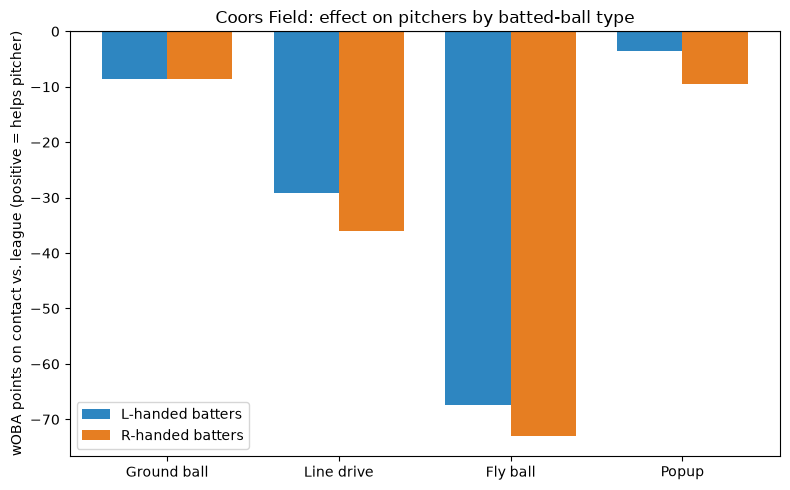

In [6]:
plot_park_bb(effects, "Coors Field", path=FIGURES / "Coors_Field_batted_balls.png")
plt.show()

## Step 2: which pitch archetypes suit each park?

Each archetype (and pitcher hand) has a mix of batted balls by batter side and type. Weighting a park's effects by that mix gives the archetype's expected park effect.

- `edge_pts`: wOBA points on contact vs. a league-average park (positive helps the pitcher)
- `fit_pts`: `edge_pts` with the park's overall effect and the archetype's overall tendency removed, so it measures how much better this park suits the pitch than it suits a typical pitch (positive = better fit)

In [7]:
arch = archetype_park_edges(contact, effects, min_bip=2000)
arch.to_csv(PROCESSED / "archetype_park_fit.csv", index=False)
archetype_batted_ball_profile(contact).to_csv(PROCESSED / "archetype_batted_ball_profile.csv", index=False)
print(arch["coverage"].min().round(3), "= lowest coverage (should be close to 1)")
best_archetypes_for_park(arch, "Coors Field", hand="R")

1.0 = lowest coverage (should be close to 1)


,archetype,p_throws,fit_pts,edge_pts
1027,Sinker | higher slot | low-IVB,R,6.875897,-22.757727
1507,Splitter | lower slot | low-IVB,R,6.542146,-23.200015
1147,Sinker | lower slot | low-IVB,R,6.137063,-23.506933
1447,Splitter | higher slot | low-IVB,R,5.539999,-24.201956
217,Changeup | lower slot | low-IVB,R,5.48009,-24.304553


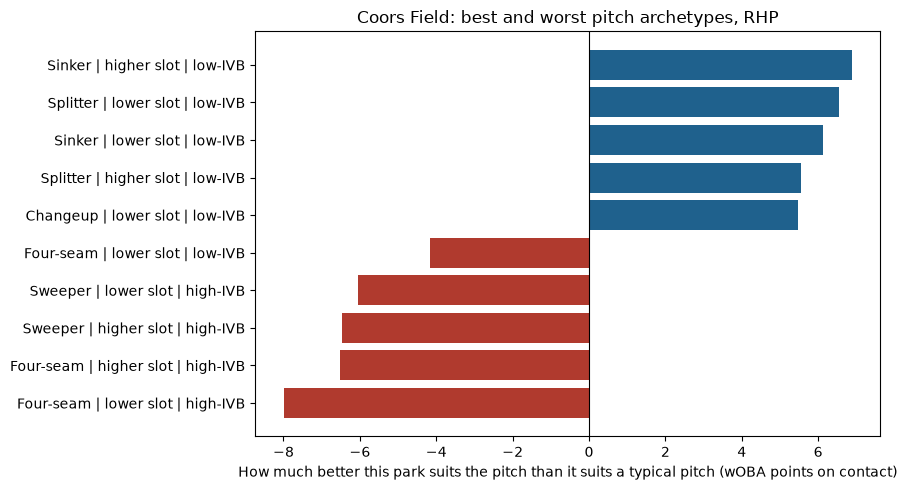

In [8]:
plot_park_archetypes(arch, "Coors Field", "R", path=FIGURES / "Coors_Field_RHP.png")
plt.show()

## Make charts for every park

Oakland Coliseum and Steinbrenner Field are skipped because no team plays there now.

In [9]:
for park in sorted(set(effects["park"]) - INACTIVE_PARKS):
    stem = park.replace(" ", "_")
    figs = [plot_park_bb(effects, park, path=FIGURES / f"{stem}_batted_balls.png")]
    for hand in ["R", "L"]:
        figs.append(plot_park_archetypes(arch, park, hand, path=FIGURES / f"{stem}_{hand}HP.png"))
    for fig in figs:
        if fig is not None:
            plt.close(fig)

## Commit

```
git add src notebooks data/processed slides/figures
git commit -m "park effects by batted-ball type, archetype fit scores"
git push
```